In [ ]:
import pandas as pd
import sklearn
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import plotly.offline as py
import plotly.graph_objs as go
from plotly.offline import init_notebook_mode, iplot
import os
import warnings
import seaborn as sns
from sklearn.datasets import make_blobs
import pickle
import gc
%matplotlib inline

In [ ]:
# 1. Load the dataset
loan = pd.read_csv("loan_data.csv")
loan.head(5)

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
loan.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


In [ ]:
# 2. Check for the null values in the dataset
loan.isnull().sum()

SK_ID_CURR                        0
TARGET                            0
NAME_CONTRACT_TYPE                0
CODE_GENDER                       0
FLAG_OWN_CAR                      0
                              ...  
AMT_REQ_CREDIT_BUREAU_DAY     41519
AMT_REQ_CREDIT_BUREAU_WEEK    41519
AMT_REQ_CREDIT_BUREAU_MON     41519
AMT_REQ_CREDIT_BUREAU_QRT     41519
AMT_REQ_CREDIT_BUREAU_YEAR    41519
Length: 122, dtype: int64

In [ ]:
# 3. Print the percentage of default to a payer of the dataset for the TARGET column
d=(loan.TARGET==1).sum()
p=(loan.TARGET==0).sum()
dp=(d/p)*100
print("Percentage of defaulter to payer of the dataset for the TARGET column",dp)

Percentage of defaulter to payer of the dataset for the TARGET column 8.781828601345662


In [ ]:
# Find if there are any duplicate rows
wid = [column for column in loan.columns if column!='SK_ID_CURR']
dup = loan[loan.duplicated(subset=wid,keep=False)]
print("Duplicates are",dup.shape[0])

Duplicates are 0


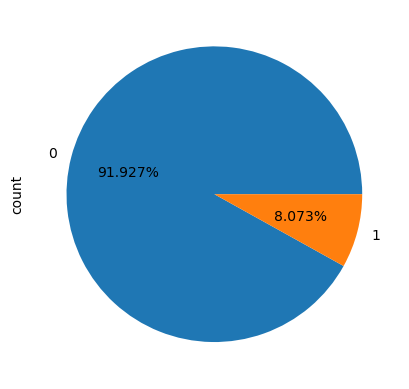

In [ ]:
loan.TARGET.value_counts().plot(kind='pie',autopct='%1.3f%%')
plt.show()

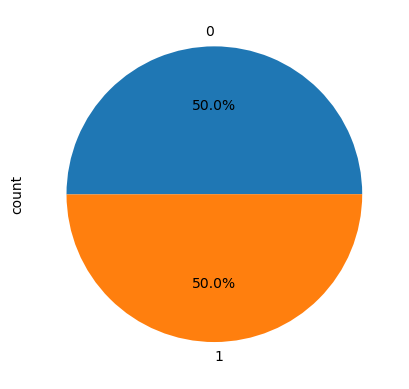

In [ ]:
# 4. Balance the dataset if the data is imbalanced
# 5. Plot the balanced or imbalanced data
s_data=loan.sample(frac=1,random_state=3)
unpaid_home_loan=s_data.loc[s_data['TARGET']==1]
paid_home_loan=s_data.loc[s_data['TARGET']==0].sample(n=24850,random_state=23)
normalised_home_loan=pd.concat([unpaid_home_loan,paid_home_loan])
normalised_home_loan.TARGET.value_counts().plot(kind='pie',autopct="%1.1f%%")
plt.show()

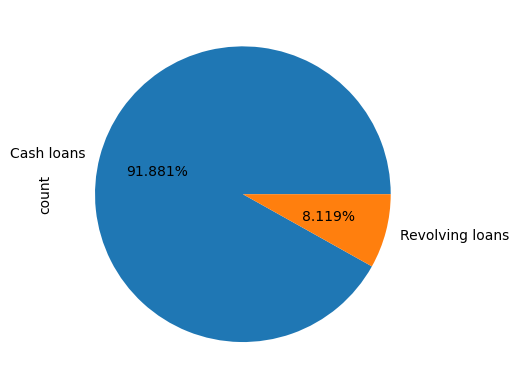

In [ ]:
normalised_home_loan.NAME_CONTRACT_TYPE.value_counts().plot(kind='pie',autopct="%1.3f%%")
plt.show()

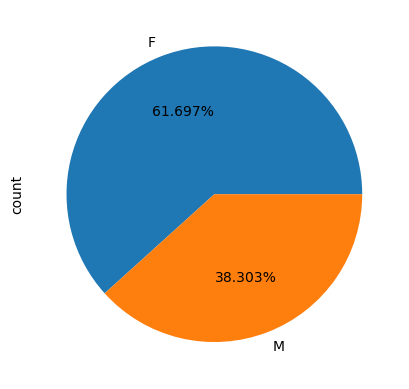

In [ ]:
normalised_home_loan.CODE_GENDER.value_counts().plot(kind='pie',autopct="%1.3f%%")
plt.show()

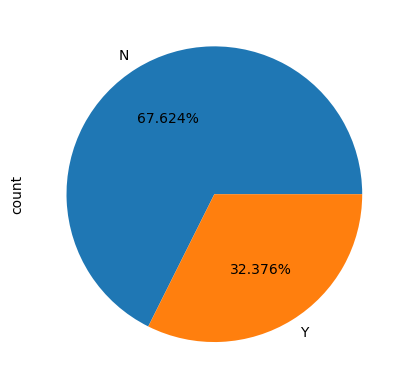

In [ ]:
normalised_home_loan.FLAG_OWN_CAR.value_counts().plot(kind='pie',autopct="%1.3f%%")
plt.show()

In [ ]:
(normalised_home_loan[normalised_home_loan['AMT_INCOME_TOTAL']>1000000]['TARGET'].value_counts())/len(normalised_home_loan[normalised_home_loan['AMT_INCOME_TOTAL'] > 1000000])*100

TARGET
0    51.851852
1    48.148148
Name: count, dtype: float64

In [ ]:
print((normalised_home_loan[normalised_home_loan['CNT_CHILDREN']>2]['TARGET'].value_counts())/len(normalised_home_loan[normalised_home_loan['CNT_CHILDREN'] > 2])*100)
print((normalised_home_loan[normalised_home_loan['CNT_CHILDREN']>5]['TARGET'].value_counts())/len(normalised_home_loan[normalised_home_loan['CNT_CHILDREN'] > 5])*100) 

TARGET
1    54.303797
0    45.696203
Name: count, dtype: float64
TARGET
1    60.0
0    40.0
Name: count, dtype: float64


In [ ]:
print((normalised_home_loan[normalised_home_loan['FLAG_OWN_CAR']=='N']['TARGET'].value_counts())/len(normalised_home_loan[normalised_home_loan['FLAG_OWN_CAR'] =='N'])*100)
print((normalised_home_loan[normalised_home_loan['FLAG_OWN_CAR']=='Y']['TARGET'].value_counts())/len(normalised_home_loan[normalised_home_loan['FLAG_OWN_CAR'] =='Y'])*100) 

TARGET
1    51.348535
0    48.651465
Name: count, dtype: float64
TARGET
0    52.894361
1    47.105639
Name: count, dtype: float64


In [ ]:
print((normalised_home_loan[normalised_home_loan['CODE_GENDER']=='M']['TARGET'].value_counts())/len(normalised_home_loan[normalised_home_loan['CODE_GENDER'] =='M'])*100) 
print((normalised_home_loan[normalised_home_loan['CODE_GENDER']=='F']['TARGET'].value_counts())/len(normalised_home_loan[normalised_home_loan['CODE_GENDER'] =='F'])*100) 


TARGET
1    55.999369
0    44.000631
Name: count, dtype: float64
TARGET
0    53.765335
1    46.234665
Name: count, dtype: float64


In [ ]:
print((normalised_home_loan[normalised_home_loan['NAME_CONTRACT_TYPE']=='Cash loans']['TARGET'].value_counts())/len(normalised_home_loan[normalised_home_loan['NAME_CONTRACT_TYPE']=='Cash loans'])*100) 
print((normalised_home_loan[normalised_home_loan['NAME_CONTRACT_TYPE']=='Revolving loans']['TARGET'].value_counts())/len(normalised_home_loan[normalised_home_loan['NAME_CONTRACT_TYPE']=='Revolving loans'])*100) 


TARGET
1    50.876386
0    49.123614
Name: count, dtype: float64
TARGET
0    60.228118
1    39.771882
Name: count, dtype: float64


In [ ]:
normalised_home_loan=normalised_home_loan.sample(frac=1,random_state=5)

In [ ]:
# 6. Encode the columns that is required for the model
from sklearn.preprocessing import OrdinalEncoder

ordenc=OrdinalEncoder()
normalised_home_loan['NAME_CONTRACT_TYPE_CODE']=ordenc.fit_transform(normalised_home_loan[['NAME_CONTRACT_TYPE']]) 
print(normalised_home_loan[['NAME_CONTRACT_TYPE','NAME_CONTRACT_TYPE_CODE']].head(20))
print(normalised_home_loan['NAME_CONTRACT_TYPE_CODE'].value_counts())

       NAME_CONTRACT_TYPE  NAME_CONTRACT_TYPE_CODE
216444         Cash loans                      0.0
285729         Cash loans                      0.0
32788          Cash loans                      0.0
245498         Cash loans                      0.0
290805         Cash loans                      0.0
104540         Cash loans                      0.0
275225         Cash loans                      0.0
272286         Cash loans                      0.0
201269         Cash loans                      0.0
102279         Cash loans                      0.0
45439          Cash loans                      0.0
241742         Cash loans                      0.0
3475           Cash loans                      0.0
166378         Cash loans                      0.0
107507         Cash loans                      0.0
143210         Cash loans                      0.0
155797         Cash loans                      0.0
2666      Revolving loans                      1.0
247643         Cash loans      

In [ ]:
normalised_home_loan['CODE_GENDER_CODE']=ordenc.fit_transform(normalised_home_loan[['CODE_GENDER']]) 
print(normalised_home_loan[['CODE_GENDER','CODE_GENDER_CODE']].head(20))
print(normalised_home_loan['CODE_GENDER_CODE'].value_counts())

       CODE_GENDER  CODE_GENDER_CODE
216444           F               0.0
285729           M               1.0
32788            F               0.0
245498           M               1.0
290805           F               0.0
104540           F               0.0
275225           M               1.0
272286           F               0.0
201269           M               1.0
102279           F               0.0
45439            F               0.0
241742           F               0.0
3475             F               0.0
166378           F               0.0
107507           F               0.0
143210           F               0.0
155797           F               0.0
2666             M               1.0
247643           F               0.0
124805           F               0.0
CODE_GENDER_CODE
0.0    30648
1.0    19027
Name: count, dtype: int64


In [ ]:
normalised_home_loan['FLAG_OWN_CAR_CODE']=ordenc.fit_transform(normalised_home_loan[['FLAG_OWN_CAR']]) 
print(normalised_home_loan[['FLAG_OWN_CAR','FLAG_OWN_CAR_CODE']].head(20))
print(normalised_home_loan['FLAG_OWN_CAR_CODE'].value_counts())

       FLAG_OWN_CAR  FLAG_OWN_CAR_CODE
216444            N                0.0
285729            Y                1.0
32788             N                0.0
245498            N                0.0
290805            N                0.0
104540            N                0.0
275225            N                0.0
272286            N                0.0
201269            Y                1.0
102279            N                0.0
45439             Y                1.0
241742            N                0.0
3475              Y                1.0
166378            N                0.0
107507            N                0.0
143210            N                0.0
155797            N                0.0
2666              Y                1.0
247643            N                0.0
124805            N                0.0
FLAG_OWN_CAR_CODE
0.0    33592
1.0    16083
Name: count, dtype: int64


In [ ]:
normalised_home_loan['CNT_CHILDREN_CODE']=ordenc.fit_transform(normalised_home_loan[['CNT_CHILDREN']]) 
print(normalised_home_loan[['CNT_CHILDREN_CODE','CNT_CHILDREN']].head(20))
print(normalised_home_loan['CNT_CHILDREN_CODE'].value_counts())

        CNT_CHILDREN_CODE  CNT_CHILDREN
216444                0.0             0
285729                2.0             2
32788                 0.0             0
245498                0.0             0
290805                1.0             1
104540                0.0             0
275225                0.0             0
272286                0.0             0
201269                0.0             0
102279                0.0             0
45439                 0.0             0
241742                0.0             0
3475                  0.0             0
166378                0.0             0
107507                0.0             0
143210                0.0             0
155797                0.0             0
2666                  4.0             4
247643                0.0             0
124805                0.0             0
CNT_CHILDREN_CODE
0.0     34085
1.0     10294
2.0      4506
3.0       675
4.0        86
5.0        14
6.0        10
8.0         2
10.0        1
9.0         1
7.

In [ ]:
normalised_home_loan=normalised_home_loan.sample(frac=1,random_state=45)

In [ ]:
normalised_home_loan['TARGET'].value_counts()

TARGET
0    24850
1    24825
Name: count, dtype: int64

In [ ]:
y=normalised_home_loan.TARGET 

In [ ]:
normalised_home_loan_features=['SK_ID_CURR','NAME_CONTRACT_TYPE_CODE','CNT_CHILDREN_CODE','FLAG_OWN_CAR_CODE','CODE_GENDER_CODE']

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
blobs_random_seed = 42
centers = [(0,0), (5,5)]
cluster_std = 1
frac_test_split = 0.33
num_features_for_samples = 2
num_samples_total = 49650

inputs, targets = make_blobs(n_samples = num_samples_total, centers = centers, n_features = num_features_for_samples, cluster_std = cluster_std)

X_train,X_test,y_train,y_test=train_test_split(inputs,targets,test_size=0.33,random_state=45)

In [ ]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(33265, 2) (16385, 2) (33265,) (16385,)


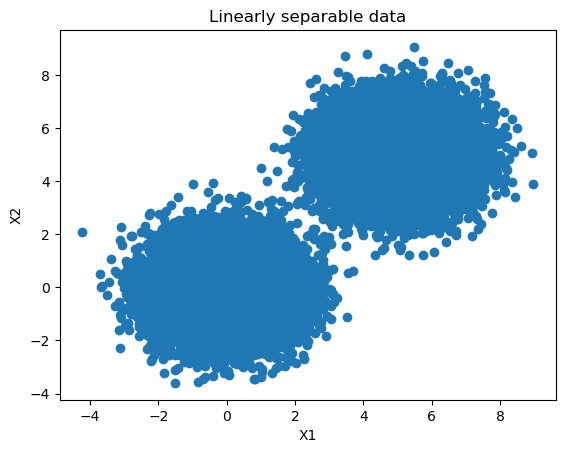

In [ ]:
plt.scatter(X_train[:,0], X_train[:,1])
plt.title('Linearly separable data')
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()

In [ ]:
from sklearn import svm 
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay

In [ ]:
clf=svm.SVC(kernel='linear')

In [ ]:
clf=clf.fit(X_train,y_train)

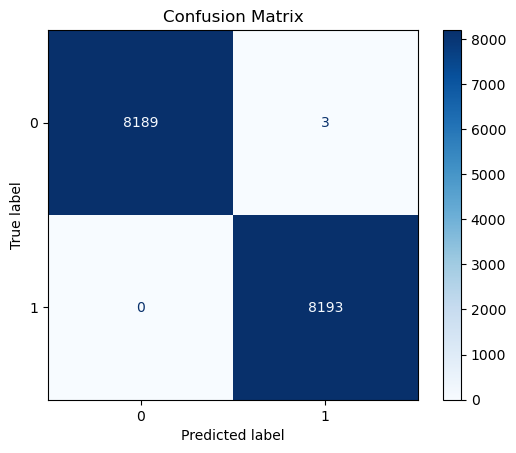

In [ ]:
predictions = clf.predict(X_test)
cm = confusion_matrix(y_test, predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()




#matrix = confusion_matrix(clf, X_test, y_test,cmap=plt.cm.Blues,normalize='true')
#plt.title('Confusion matrix')
#plt.show(matrix)
#plt.show()

In [ ]:
from sklearn.metrics import precision_score, recall_score,f1_score,roc_curve,auc


In [ ]:
# 7.Calculate Sensitivity as a metric
print(precision_score(y_test, predictions))
print(recall_score(y_test, predictions)) 
print(f1_score(y_test,predictions,average=None))

0.9996339677891655
1.0
[0.99981686 0.99981695]


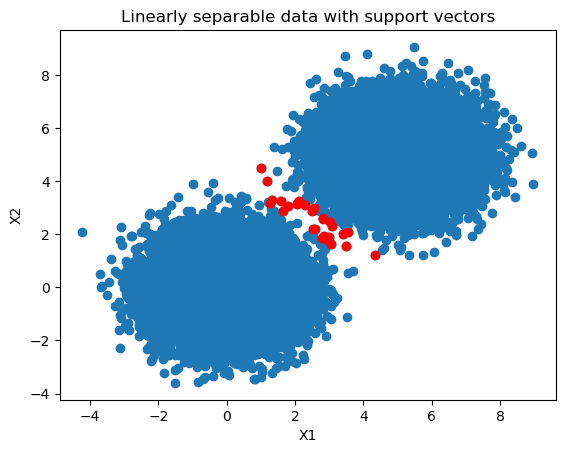

In [ ]:
support_vectors = clf.support_vectors_

# Visualize support vectors
plt.scatter(X_train[:,0], X_train[:,1])
plt.scatter(support_vectors[:,0], support_vectors[:,1], color='red')
plt.title('Linearly separable data with support vectors')
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()

Area under ROC 0.99981689453125


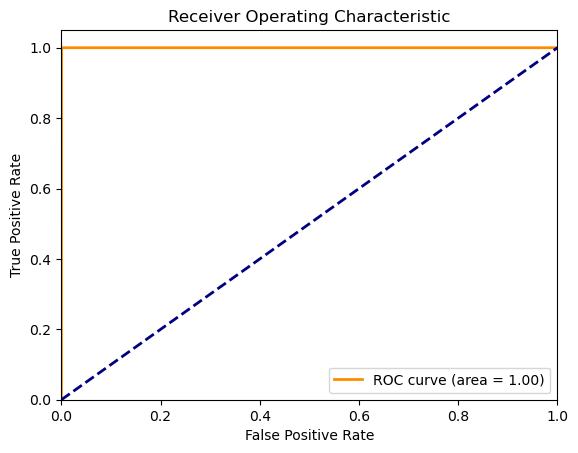

In [ ]:
# 8. Calculate the area under  the receiver operating characteristics curve
fpr, tpr, thresholds = roc_curve(y_test, predictions)
roc_auc = auc(fpr, tpr)
print("Area under ROC",roc_auc)
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()